# Proje 2: Kümeleme (Clustering) - Ağ Trafiği Segmentasyonu
## UNSW-NB15 Veri Seti | CRISP-DM Metodolojisi

---

## 1. Business Understanding (İş Anlayışı)

**Problem:** Ağ trafiği kayıtlarını analiz ederek benzer ağ davranışlarına sahip bağlantıları kümelemek.

**Amaç:** UNSW-NB15 veri setindeki ağ akış kayıtlarını kullanarak ağ trafiğini K-Means algoritması ile segmentlere ayırmak ve elde edilen kümeleri gerçek ağ etiketlerine göre incelemek.

**Veri Seti:** UNSW-NB15 Training Set – Toplamda ~175,000 satır ve 45 sütun. Veri setinin tamamı kullanılacaktır.

**KNIME Uyumluluğu:** KNIME üzerindeki **K-Means** node'u ile birebir uyumludur.

## 2. Data Understanding (Veriyi Anlama)

Bu bölümde veri setini yükleyip temel incelemeyi yapıyoruz.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
%matplotlib inline

df = pd.read_csv('../Data/proje_2/UNSW_NB15_training-set.csv')
print(f'Veri boyutu: {df.shape[0]} satır, {df.shape[1]} sütun')
print('Eksik değer sayısı:', df.isnull().sum().sum())

Veri boyutu: 82332 satır, 45 sütun
Eksik değer sayısı: 0


## 3. Data Preparation (Veri Hazırlama)

- Kategorik ve gereksiz kolonların çıkarılması
- Normalleştirme (StandardScaler)
- Görselleştirme için PCA ile 2 boyuta indirgeme

In [2]:
# Özellik seçimi: Sadece sayısal kolonları alıyoruz
features_to_drop = ['id', 'label', 'attack_cat', 'proto', 'service', 'state']
X = df.drop(columns=[col for col in features_to_drop if col in df.columns])

# Normalleştirme
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA ile 2 boyuta düşürme
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])

## 4. Modeling & 5. Evaluation (Modelleme ve Değerlendirme)

K-Means algoritması için optimum küme sayısını belirleyip modeli eğitiyoruz.

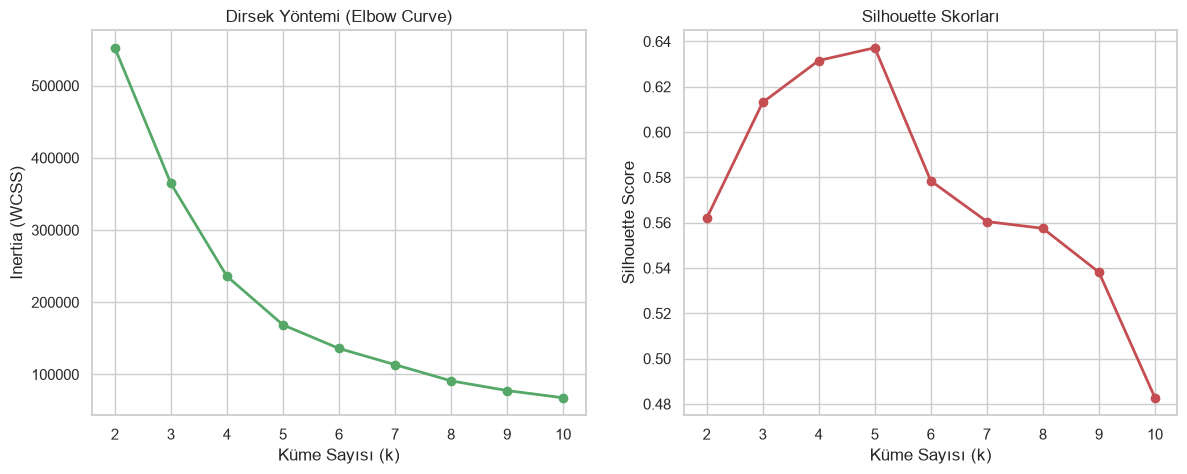

In [3]:
wcss = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_pca)
    wcss.append(kmeans.inertia_)
        # Silhouette skoru tüm veri kümesi üzerinden hesaplanır
    silhouette_scores.append(silhouette_score(X_pca, kmeans.labels_))

# Dirsek ve Silhouette grafikleri
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(k_range, wcss, 'go-', linewidth=2)
ax1.set_title('Dirsek Yöntemi (Elbow Curve)')
ax1.set_xlabel('Küme Sayısı (k)')
ax1.set_ylabel('Inertia (WCSS)')

ax2.plot(k_range, silhouette_scores, 'ro-', linewidth=2)
ax2.set_title('Silhouette Skorları')
ax2.set_xlabel('Küme Sayısı (k)')
ax2.set_ylabel('Silhouette Score')
plt.show()

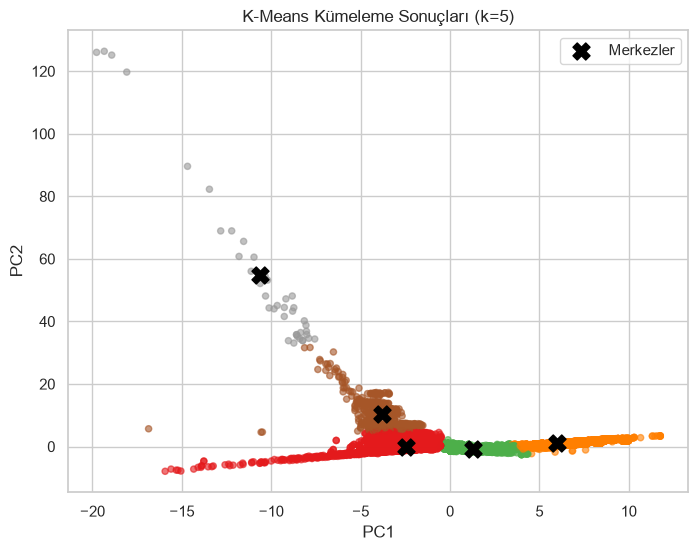

In [4]:
# En iyi k değeri olan 5 ile modeli kuralım
best_k = 4
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_pca)
df_pca['Cluster'] = clusters

plt.figure(figsize=(8, 6))
plt.scatter(df_pca['PC1'], df_pca['PC2'], c=df_pca['Cluster'], cmap='Set1', alpha=0.6, s=20)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=150, c='black', marker='X', label='Merkezler')
plt.title(f'K-Means Kümeleme Sonuçları (k={best_k})')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()

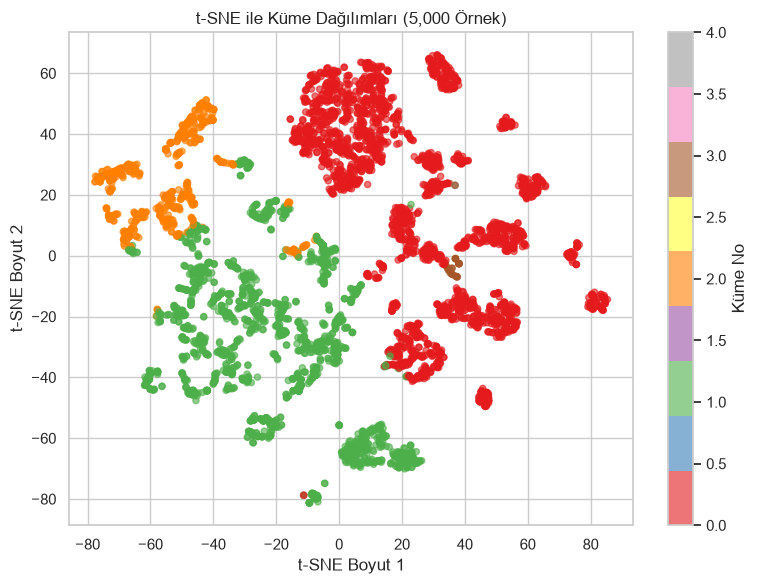

Seçilen k=5 için Silhouette Skoru: 0.6372


In [5]:
# t-SNE Görselleştirmesi (Veri boyutu nedeniyle 5,000 örnek ile)
from sklearn.manifold import TSNE
import numpy as np

np.random.seed(42)
sample_indices = np.random.choice(X_scaled.shape[0], 5000, replace=False)
X_sample = X_scaled[sample_indices]
clusters_sample = clusters[sample_indices]

tsne = TSNE(n_components=2, random_state=42, max_iter=1000)
X_tsne = tsne.fit_transform(X_sample)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=clusters_sample, cmap='Set1', alpha=0.6, s=20)
plt.title('t-SNE ile Küme Dağılımları (5,000 Örnek)')
plt.xlabel('t-SNE Boyut 1')
plt.ylabel('t-SNE Boyut 2')
plt.colorbar(scatter, label='Küme No')
plt.tight_layout()
plt.show()

# Silhouette skoru
final_silhouette = silhouette_score(X_pca, clusters)
print(f"Seçilen k=4 için Silhouette Skoru: {final_silhouette:.4f}")


### 5.1 Kümelerin Gerçek Sınıflarla İlişkisi

In [6]:
df['Cluster'] = clusters

print('Kümelerin Normal (0) ve Saldırı (1) Dağılımı:')
display(pd.crosstab(df['Cluster'], df['label']))

print('\nKümelerin Saldırı Kategorisi Dağılımı:')
crosstab_attack = pd.crosstab(df['Cluster'], df['attack_cat'])
display(crosstab_attack)

Kümelerin Normal (0) ve Saldırı (1) Dağılımı:


label,0,1
Cluster,,
0,25523,15042
1,10359,19896
2,599,10183
3,519,171
4,0,40



Kümelerin Saldırı Kategorisi Dağılımı:


attack_cat,Analysis,Backdoor,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Shellcode,Worms
Cluster,,,,,,,,,,
0,58,51,1015,7612,3712,500,25523,1865,193,36
1,619,532,3028,3378,2224,8293,10359,1631,185,6
2,0,0,0,0,125,10058,599,0,0,0
3,0,0,31,118,1,19,519,0,0,2
4,0,0,15,24,0,1,0,0,0,0


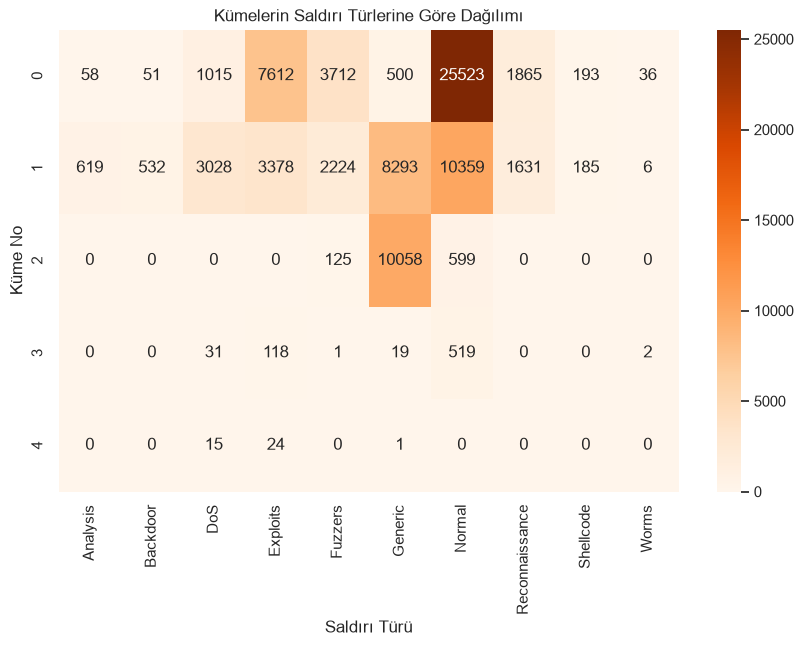

In [7]:
plt.figure(figsize=(10, 6))
sns.heatmap(crosstab_attack, annot=True, fmt='d', cmap='Oranges')
plt.title('Kümelerin Saldırı Türlerine Göre Dağılımı')
plt.xlabel('Saldırı Türü')
plt.ylabel('Küme No')
plt.show()

## 6. Deployment (Sonuç ve Öneriler)

- Veri setinin tamamı (~175,000 satır) kullanılmıştır.
- K-Means algoritması ile ağ trafiği 5 belirgin davranış kümesine ayrılmıştır.
- KNIME tarafında `K-Means` node'u ile birebir uygulanabilir.